# Tarea 03: Generación de imágenes con autoencoders
### PyTorch Lightning · Hydra · Weights & Biases

**Curso:** Inteligencia Artificial — Escuela de Ingeniería en Computación, Instituto Tecnológico de Costa Rica

**Integrantes:**
- Sebastián Chacón - 2023221908
- Daniel Pulido - 2019196502
- Sebastián Muñoz - 2023090681

**Objetivo:** comparar un *Variational Autoencoder* (VAE) y un autoencoder U-Net (con *skip connections*) en la reconstrucción de imágenes de MVTec AD, entrenando cada uno con cuatro funciones de pérdida (L1, L2, SSIM y SSIM + L1) y analizando su capacidad para distinguir imágenes normales de imágenes con anomalías.

> Todas las figuras de resultados de este notebook se generan y registran en Weights & Biases y luego se insertan aquí (descargándolas con la API de W&B).

## Contenido
1. Configuración del entorno
2. Dataset (MVTec AD)
3. Configuración de experimentos con Hydra
4. Modelos
5. Funciones de pérdida
6. Entrenamiento (trials de hiperparámetros, sin repetir corridas)
7. Seguimiento de los entrenamientos en W&B
8. Evaluación del modelo
9. Comparación entre configuraciones
10. Conclusiones

## 1. Configuración del entorno

### 1.1 Entorno virtual (`.venv`)
El proyecto usa un entorno virtual propio con **Python 3.11** (Hydra y Lightning son más estables en 3.11 que en 3.14). Se crea **una sola vez** desde una terminal en la raíz del repositorio, antes de abrir el notebook, porque el notebook tiene que ejecutarse *dentro* de ese entorno:

```powershell
py -3.11 -m venv .venv
.venv\Scripts\python -m pip install --upgrade pip
# PyTorch con CUDA (GPU NVIDIA). Sin GPU: quitar --index-url para instalar la versión CPU
.venv\Scripts\python -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130
.venv\Scripts\python -m pip install -r requirements.txt
# Registrar el entorno como kernel de Jupyter
.venv\Scripts\python -m ipykernel install --user --name autoencoder --display-name "Python (.venv Autoencoder)"
```

Luego, en VS Code: **Select Kernel → Python Environments → `.venv`** (o el kernel *Python (.venv Autoencoder)* en Jupyter).
La siguiente celda verifica que el notebook esté corriendo con el Python del `.venv`, imprime las versiones y si hay GPU.

### 1.2 Imports, versiones y directorio de trabajo
El notebook vive en `notebooks/`, pero `train.py`, `conf/` y `data/` usan rutas relativas a la raíz del repositorio, así que se cambia el directorio de trabajo a la raíz.

In [1]:
# Imports, versiones de librerías, GPU y directorio de trabajo
import os
import sys
from pathlib import Path

# The notebook lives in notebooks/; train.py, conf/ and data/ are relative to the repo root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import logging
import warnings

# Hide noise that does not affect the results: torch's "triton not found" (no triton on Windows) and deprecation notices
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import hydra
import lightning as L
import pandas as pd
import plotly
import torch
import torchmetrics
import torchvision
import wandb
from omegaconf import OmegaConf
from IPython.display import Image, display

print("Raíz del repo:", ROOT)
print("Python       :", sys.executable)
if ".venv" not in sys.executable:
    print("ADVERTENCIA: el kernel no es el del .venv (ver 1.1)")
for name, module in [("torch", torch), ("torchvision", torchvision), ("lightning", L), ("hydra-core", hydra),
                     ("wandb", wandb), ("torchmetrics", torchmetrics), ("plotly", plotly), ("pandas", pd)]:
    print(f"{name:<13}: {module.__version__}")
print("GPU          :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible (CPU)")

Raíz del repo: c:\Users\Chaco\OneDrive\Documents\GitHub\Autoencoder
Python       : c:\Users\Chaco\OneDrive\Documents\GitHub\Autoencoder\.venv\Scripts\python.exe
torch        : 2.14.1+cu130
torchvision  : 0.29.1+cu130
lightning    : 2.6.6
hydra-core   : 1.3.8
wandb        : 0.31.0
torchmetrics : 1.9.0
plotly       : 7.1.0
pandas       : 3.1.0
GPU          : NVIDIA GeForce RTX 4060


### 1.3 Weights & Biases
Todos los experimentos se registran en el **team** de W&B del grupo ([danielpulido-instituto-tecnol-gico-de-costa-rica](https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/members)), proyecto `Autoencoder`, ambos definidos en `conf/logger/wandb.yaml`. **Cada integrante inicia sesión con su propia cuenta** (su propia API key) y, como todos pertenecen al team, las corridas de todos quedan en el mismo proyecto, firmadas con el usuario que las lanzó. Cada corrida se llama `<modelo>-<pérdida>-<trial>` (por ejemplo `vae-ssim_l1-e200`; ver 6.1), se agrupa por modelo, lleva como tags el modelo, la pérdida y el trial y guarda la configuración completa de Hydra. Durante el entrenamiento se registran:

| Clave en W&B | Contenido |
|---|---|
| `train/loss`, `val/loss` | pérdida de entrenamiento y validación por época (la función de pérdida de la corrida + β·KL en el VAE) |
| `train/l1`, `val/mse`, `val/ssim`, ... | métricas comunes a todas las corridas, para comparar en la misma escala |
| `val/reconstructions` | 16 imágenes de validación: originales vs reconstruidas (cada 5 épocas) |
| `val/tsne` | t-SNE del vector latente del set de validación (cada 10 épocas) |
| `test/reconstructions` | 8 imágenes buenas + 8 defectuosas del set de prueba con su reconstrucción y mapa de error |
| `test/tsne` | t-SNE del set de prueba (good vs defective) |
| `test/scores` | tabla con el error de reconstrucción de cada imagen de prueba (para los histogramas) |
| `test/auroc_*` | AUROC del error de reconstrucción como detector de anomalías (global y por clase) |

**Comandos útiles** (terminal con el `.venv` activo, o con `!` desde una celda):

| Comando | Para qué |
|---|---|
| `wandb login --relogin` | pide y guarda la API key de **tu** cuenta (reemplaza la que hubiera guardada en el archivo `_netrc` de tu carpeta de usuario); equivale a `wandb.login(relogin=True)` |
| `wandb offline` / `wandb online` | desactiva / reactiva la sincronización para todo el directorio |
| `wandb sync <carpeta>/wandb/offline-run-*` | sube a W&B una corrida que se hizo en modo offline |
| `python train.py logger.wandb.mode=disabled` | entrena sin registrar nada en W&B |
| `python train.py logger.wandb.entity=null` | registra en tu cuenta personal en vez del team (pruebas) |

La celda siguiente usa `relogin=True`, así que **siempre pide la API key** (la de tu cuenta personal, en *User settings → API keys*). Queda guardada en el equipo y los entrenamientos lanzados desde este notebook (sección 6) la reutilizan. Al final imprime con qué usuario quedó la sesión: verificar que sea el tuyo.

In [2]:
# Inicio de sesión en W&B con la cuenta propia (pide la API key)
from getpass import getpass

wandb_cfg = OmegaConf.load(ROOT / "conf" / "logger" / "wandb.yaml").wandb
WANDB_PROJECT = wandb_cfg.project  # Autoencoder
WANDB_ENTITY = wandb_cfg.entity    # team of the group (same value train.py uses)

# Asks for the key directly (avoids wandb's interactive 1/2/3 menu) and saves it for train.py
api_key = getpass("Pega tu API key de W&B y presiona Enter: ").strip()
wandb.login(key=api_key, relogin=True, verify=True)
del api_key

print("Usuario de W&B:", wandb.Api().viewer.username)
print("Destino       :", f"{WANDB_ENTITY}/{WANDB_PROJECT}")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.forge.coreweave.com.
wandb: Appending key for api.forge.coreweave.com to your netrc file: C:\Users\Chaco\_netrc
wandb: Currently logged in as: chaco17 to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


Usuario de W&B: chaco17
Destino       : danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder


Funciones auxiliares para que las figuras que se construyen en el notebook también pasen por W&B: se registran en una corrida aparte (`job_type="analysis"`, no se mezcla con los entrenamientos) y luego se muestran aquí.

In [3]:
# Funciones auxiliares para registrar figuras en W&B y mostrarlas
from PIL import Image as PILImage


def start_notebook_run(name):
    # W&B run where the notebook logs its own figures (kept apart from the training runs)
    wandb.finish()
    return wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY, name=name, job_type="analysis")


def log_and_show(run, key, fig=None, image=None, caption=None):
    # Log a plotly figure or an image to W&B and display it in the notebook
    if fig is not None:
        run.log({key: wandb.Plotly(fig)})
        fig.show()
    if image is not None:
        img = PILImage.open(image) if isinstance(image, (str, Path)) else image
        run.log({key: wandb.Image(img, caption=caption)})
        if caption:
            print(caption)
        display(img)


def show_image(path, title=None):
    # Display an image downloaded from W&B
    if title:
        print(title)
    display(Image(filename=str(path)))

## 2. Dataset (MVTec AD)
*MVTec AD — A Comprehensive Real-World Dataset for Unsupervised Anomaly Detection* contiene imágenes industriales de 15 objetos/texturas. El conjunto de **entrenamiento** solo tiene imágenes sin defectos (`good`), y el de **prueba** mezcla imágenes buenas con distintos tipos de defectos. Por eso es un problema de detección de anomalías **no supervisada**: el autoencoder aprende a reconstruir lo "normal" y se espera que reconstruya peor lo defectuoso.

Para reducir el tiempo de entrenamiento se usan solo 4 clases: **cable, capsule, screw y transistor**.

### 2.1 Estructura y cantidad de imágenes
Se descargaron los archivos `cable.tar.xz`, `capsule.tar.xz`, `screw.tar.xz` y `transistor.tar.xz` de la página oficial y se extrajeron en `data/mvtec_ad/` (la carpeta `data/` no se sube a git):

```bash
mkdir -p data/mvtec_ad
for c in cable capsule screw transistor; do tar -xJf ~/Downloads/$c.tar.xz -C data/mvtec_ad; done
```

Estructura resultante: `data/mvtec_ad/<clase>/train/good/`, `data/mvtec_ad/<clase>/test/<good|tipo_de_defecto>/` y `ground_truth/` (máscaras, no se usan). La siguiente celda verifica la estructura y cuenta las imágenes por clase y tipo de defecto.

In [4]:
# Verificación del dataset y conteo de imágenes por clase/defecto
from collections import Counter

from src.data import list_samples

DATA_ROOT = ROOT / "data" / "mvtec_ad"
CLASSES = ["cable", "capsule", "screw", "transistor"]

missing = [c for c in CLASSES if not (DATA_ROOT / c / "train" / "good").is_dir()]
assert not missing, f"Faltan clases en {DATA_ROOT}: {missing} (ver 2.1)"

train_samples = list_samples(DATA_ROOT, CLASSES, "train")
test_samples = list_samples(DATA_ROOT, CLASSES, "test")

test_df = pd.DataFrame([(c, d) for _, c, d in test_samples], columns=["clase", "defecto"])
summary = pd.DataFrame({
    "train (good)": pd.Series(Counter(c for _, c, _ in train_samples)),
    "test good": test_df[test_df.defecto == "good"].clase.value_counts(),
    "test defectuosas": test_df[test_df.defecto != "good"].clase.value_counts(),
    "tipos de defecto": test_df[test_df.defecto != "good"].groupby("clase").defecto.nunique(),
}).loc[CLASSES]
summary.loc["total"] = summary.sum()
display(summary)

print("Imágenes de prueba por tipo de defecto:")
display(test_df.groupby(["clase", "defecto"]).size().rename("n").to_frame())

,train (good),test good,test defectuosas,tipos de defecto
cable,224,58,92,8
capsule,219,23,109,5
screw,320,41,119,5
transistor,213,60,40,4
total,976,182,360,22


Imágenes de prueba por tipo de defecto:


n
clase      defecto                 
cable      bent_wire             13
           cable_swap            12
           combined              11
           cut_inner_insulation  14
           cut_outer_insulation  10
           good                  58
           missing_cable         12
           missing_wire          10
           poke_insulation       10
capsule    crack                 23
           faulty_imprint        22
           good                  23
           poke                  21
           scratch               23
           squeeze               20
screw      good                  41
           manipulated_front     24
           scratch_head          24
           scratch_neck          25
           thread_side           23
           thread_top            23
transistor bent_lead             10
           cut_lead              10
           damaged_case          10
           good                  60
           misplaced             10

### 2.2 Preprocesamiento: 128x128 con 3 canales
Las imágenes originales son de alta resolución (entre 1000x1000 y 1024x1024; *screw* además está en escala de grises). Al cargarlas (`src/data.py`):
- se convierten a **RGB** (screw pasa de 1 a 3 canales repitiendo el canal gris),
- se redimensionan a **128x128** con interpolación bilineal,
- se guardan en memoria como `uint8` y se convierten a `float` en **[0, 1]** al pedir un batch. El rango [0, 1] coincide con la salida `Sigmoid` de ambos modelos y con el `data_range=1` de SSIM.

No se usa *data augmentation*: el objetivo es aprender la apariencia "normal" de cada objeto, y transformaciones como rotaciones podrían parecerse a defectos (p. ej. `misplaced` en transistor).

La configuración del dataset se lee del archivo de Hydra `conf/data/mvtec.yaml`.

In [5]:
# Carga del DataModule y forma de un batch
from omegaconf import OmegaConf

from src.data import MVTecDataModule

data_cfg = OmegaConf.load(ROOT / "conf" / "data" / "mvtec.yaml")
print(OmegaConf.to_yaml(data_cfg))

dm = MVTecDataModule(**data_cfg)
dm.setup()  # loads and resizes every image once (can take a minute)

batch = next(iter(dm.train_dataloader()))
x = batch["image"]
print("Batch:", tuple(x.shape), x.dtype, f"rango [{x.min():.2f}, {x.max():.2f}]")
print("Clases en el batch:", Counter(batch["category"]))

root: data/mvtec_ad
classes:
- cable
- capsule
- screw
- transistor
img_size: 128
batch_size: 32
val_split: 0.15
num_workers: 0

Batch: (32, 3, 128, 128) torch.float32 rango [0.04, 1.00]
Clases en el batch: Counter({'screw': 12, 'cable': 9, 'transistor': 6, 'capsule': 5})


### 2.3 División del dataset (entrenamiento / validación / prueba)
- **Entrenamiento y validación** salen solo de `train/good`: se separa un 15 % (`val_split`) **de cada clase**, para que la validación contenga los 4 objetos. La validación mide qué tan bien se reconstruyen imágenes normales que el modelo no vio.
- **Prueba** es la carpeta `test/` completa: imágenes buenas y defectuosas. Solo se usa al final, con el mejor checkpoint (menor `val/loss`).

,train,val,test
cable,190,34,150
capsule,186,33,132
screw,272,48,160
transistor,181,32,100
total,829,147,542


Test good / defective: Counter({'defective': 360, 'good': 182})


Fila 1: good. Fila 2: defectuosas (bent_wire, cut_inner_insulation, crack, poke, manipulated_front, scratch_neck, bent_lead, damaged_case)


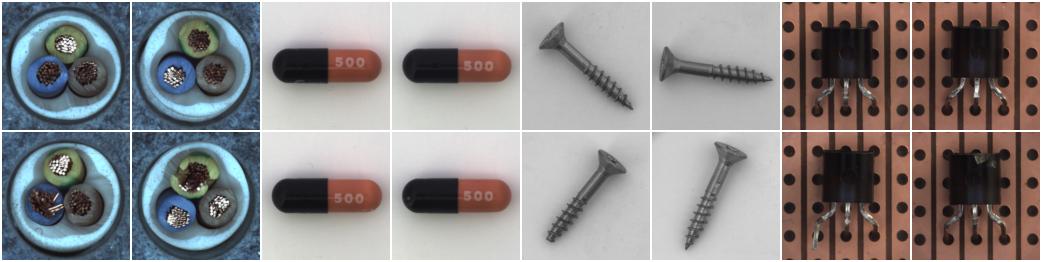

In [6]:
# Tamaños de los splits y ejemplos del set de prueba (vía W&B)
from torchvision.transforms.functional import to_pil_image
from torchvision.utils import make_grid

from src.callbacks import spread_indices

splits = {"train": dm.train_dataset, "val": dm.val_dataset, "test": dm.test_dataset}
sizes = pd.DataFrame({name: pd.Series(Counter(ds.categories)) for name, ds in splits.items()}).loc[CLASSES]
sizes.loc["total"] = sizes.sum()
display(sizes)
print("Test good / defective:", Counter("good" if l == 0 else "defective" for l in dm.test_dataset.labels))

# Examples: first row good, second row defective (2 per class), logged to W&B and shown here
ds = dm.test_dataset
good = [i for i, l in enumerate(ds.labels) if l == 0]
bad = [i for i, l in enumerate(ds.labels) if l == 1]
idx = spread_indices(good, ds.categories, 8) + spread_indices(bad, ds.categories, 8)
grid = make_grid(ds.get_images(idx), nrow=8, padding=2, pad_value=1.0)

dataset_run = start_notebook_run("notebook-dataset")
log_and_show(dataset_run, "dataset/test_examples", image=to_pil_image(grid),
             caption="Fila 1: good. Fila 2: defectuosas (" + ", ".join(ds.defects[i] for i in idx[8:]) + ")")

## 3. Configuración de experimentos con Hydra
Toda la configuración vive en `conf/` y se separa por responsabilidad, de modo que cambiar el modelo, la pérdida o el entrenamiento es solo elegir otro archivo o sobrescribir un valor:

```
conf/
├── config.yaml        # compone un archivo de cada grupo + semilla, nombre de la corrida y el sweep
├── data/mvtec.yaml    # ruta, clases, tamaño de imagen, batch size, split de validación
├── model/
│   ├── vae.yaml       # red (_target_: src.models.vae.VAE), latent_dim (z), β del KL, optimizador
│   └── u-net.yaml     # red (_target_: src.models.unet.UNet), latent_dim, optimizador
├── loss/              # l1.yaml, l2.yaml, ssim.yaml, ssim_l1.yaml (_target_ de cada pérdida)
├── trainer/default.yaml   # argumentos del Trainer de Lightning (épocas, GPU, precisión)
├── trial/                 # conjuntos de hiperparámetros de entrenamiento (base, e200_cos, e200_cos_z256), ver 6.1
└── logger/wandb.yaml      # WandbLogger (proyecto, nombre, tags) y frecuencia de las figuras
```

- La lista `defaults` de `config.yaml` elige la opción de cada grupo (`model: vae`, `loss: l1`, `trial: base`, ...).
- Los archivos de `trial/` usan `# @package _global_`: no son un bloque propio sino que **sobrescriben valores de los otros grupos** (`trainer.max_epochs`, `data.batch_size`), por eso van después de ellos en `defaults`.
- Los bloques con `_target_` se construyen con `hydra.utils.instantiate`, así `train.py` no tiene código específico de cada modelo o pérdida.
- Desde la línea de comandos se puede cambiar un grupo (`model=u-net`), un valor (`model.net.latent_dim=64`, `trainer.max_epochs=50`) o barrer varias opciones con `-m` (multirun).

La celda siguiente compone la configuración con la API de Hydra, igual que lo hace `train.py`.

In [7]:
# Composición de la configuración con Hydra
from hydra import compose, initialize_config_dir
from hydra.utils import instantiate

CONF_DIR = str(ROOT / "conf")


def load_cfg(overrides=()):
    # Compose conf/config.yaml with optional overrides, exactly as `python train.py <overrides>` would
    with initialize_config_dir(config_dir=CONF_DIR, version_base=None):
        return compose(config_name="config", overrides=list(overrides))


cfg = load_cfg()
print(OmegaConf.to_yaml(cfg))

data:
  root: data/mvtec_ad
  classes:
  - cable
  - capsule
  - screw
  - transistor
  img_size: 128
  batch_size: 32
  val_split: 0.15
  num_workers: 0
model:
  name: vae
  beta: 0.001
  net:
    _target_: src.models.vae.VAE
    in_channels: 3
    img_size: ${data.img_size}
    latent_dim: 128
    base_channels: 32
  optimizer:
    _target_: torch.optim.Adam
    _partial_: true
    lr: 0.001
    weight_decay: 0.0
loss:
  name: l1
  fn:
    _target_: torch.nn.L1Loss
trainer:
  _target_: lightning.pytorch.Trainer
  max_epochs: 100
  accelerator: auto
  devices: 1
  precision: 32
  log_every_n_steps: 5
  deterministic: false
  enable_progress_bar: true
  gradient_clip_val: 1.0
logger:
  wandb:
    _target_: lightning.pytorch.loggers.WandbLogger
    project: Autoencoder
    entity: danielpulido-instituto-tecnol-gico-de-costa-rica
    name: ${run_name}
    group: ${model.name}
    tags:
    - ${model.name}
    - ${loss.name}
    - ${trial.name}
    mode: online
    log_model: false
    sa

Ejemplo de *overrides*: U-Net con SSIM + L1 y espacio latente de 64. Equivale a `python train.py model=u-net loss=ssim_l1 model.net.latent_dim=64`.

In [8]:
# Ejemplo de overrides de Hydra
cfg_example = load_cfg(["model=u-net", "loss=ssim_l1", "model.net.latent_dim=64"])
print(OmegaConf.to_yaml(cfg_example.model))
print(OmegaConf.to_yaml(cfg_example.loss))

name: u-net
beta: 0.0
net:
  _target_: src.models.unet.UNet
  in_channels: 3
  img_size: ${data.img_size}
  latent_dim: 64
  base_channels: 32
optimizer:
  _target_: torch.optim.Adam
  _partial_: true
  lr: 0.001
  weight_decay: 0.0

name: ssim_l1
fn:
  _target_: src.losses.SSIML1Loss
  alpha: 0.85



## 4. Modelos
Ambos modelos reciben imágenes de 3x128x128, devuelven la reconstrucción en [0, 1] (`Sigmoid`) y un vector latente `z` que se usa para el t-SNE. Se entrenan con el mismo `LightningModule` (`src/module.py`), que recibe la red, la pérdida y el optimizador ya construidos por Hydra.

### 4.1 Variational Autoencoder (VAE)
`src/models/vae.py`
- **Encoder:** 4 convoluciones con stride 2 (128 → 64 → 32 → 16 → 8) con BatchNorm y LeakyReLU; el mapa de 256x8x8 se aplana y dos capas lineales producen la media $\mu$ y el log-varianza $\log\sigma^2$ de $q(z|x)$, con $z \in \mathbb{R}^{128}$ (`latent_dim`).
- **Truco de reparametrización:** $z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I)$, para que el muestreo sea diferenciable. En evaluación se usa $z = \mu$.
- **Decoder:** capa lineal a 256x8x8 y 4 convoluciones transpuestas de vuelta a 128x128.
- **Pérdida:** $\mathcal{L} = \mathcal{L}_{rec}(x, \hat{x}) + \beta \, KL\left(q(z|x) \,\|\, \mathcal{N}(0, I)\right)$ con $\beta = 0.001$. El término KL ordena el espacio latente; un $\beta$ pequeño evita que domine sobre la reconstrucción (imágenes borrosas).

Toda la información tiene que pasar por el cuello de botella de 128 números, por lo que el VAE no puede copiar detalles finos: eso es lo que debería hacer que los defectos no se reconstruyan.

In [9]:
# Construcción y resumen del VAE
from lightning.pytorch.utilities.model_summary import ModelSummary

from src.module import AutoencoderModule


def build_module(cfg):
    # Same construction as train.py: network, loss and optimizer come from the Hydra config
    return AutoencoderModule(
        net=instantiate(cfg.model.net),
        loss_fn=instantiate(cfg.loss.fn),
        optimizer=instantiate(cfg.model.optimizer),
        beta=cfg.model.beta,
    )


def describe(module, x):
    print(ModelSummary(module, max_depth=2))
    with torch.no_grad():
        out = module.eval()(x)
    for key, value in out.items():
        print(f"{key:<7}: {None if value is None else tuple(value.shape)}")


vae_module = build_module(load_cfg(["model=vae"]))
describe(vae_module, x[:4])

  | Name          | Type       | Params | Mode  | FLOPs
-------------------------------------------------------------
0 | net           | VAE        | 7.7 M  | train | 0    
1 | net.encoder   | Sequential | 691 K  | train | 0    
2 | net.fc_mu     | Linear     | 2.1 M  | train | 0    
3 | net.fc_logvar | Linear     | 2.1 M  | train | 0    
4 | net.fc_dec    | Linear     | 2.1 M  | train | 0    
5 | net.decoder   | Sequential | 706 K  | train | 0    
6 | loss_fn       | L1Loss     | 0      | train | 0    
-------------------------------------------------------------
7.7 M     Trainable params
0         Non-trainable params
7.7 M     Total params
30.821    Total estimated model params size (MB)
41        Modules in train mode
0         Modules in eval mode
0         Total Flops
recon  : (4, 3, 128, 128)
z      : (4, 128)
mu     : (4, 128)
logvar : (4, 128)


### 4.2 Autoencoder U-Net
`src/models/unet.py`
- **Encoder:** bloques `DoubleConv` (2 × [conv 3x3 + BatchNorm + ReLU]) con MaxPool entre niveles: 32 → 64 → 128 → 256 canales y un cuello de botella de 128x8x8.
- **Decoder:** convoluciones transpuestas que duplican la resolución y, en cada nivel, **concatenan el mapa del encoder de la misma resolución (*skip connection*)** antes de otro `DoubleConv`.
- **Vector latente:** el promedio global del cuello de botella (128 valores) se usa como `z` para el t-SNE. No hay término KL ($\beta = 0$).

Las *skip connections* dan al decoder acceso directo a los detalles de alta resolución, así que la U-Net reconstruye mucho más nítido que el VAE. El riesgo para detección de anomalías es que también puede "copiar" los defectos a través de las skips, reduciendo la diferencia de error entre imágenes buenas y defectuosas. Esta es una de las hipótesis a revisar en los resultados.

In [10]:
# Construcción y resumen de la U-Net
unet_module = build_module(load_cfg(["model=u-net"]))
describe(unet_module, x[:4])

  | Name           | Type       | Params | Mode  | FLOPs
--------------------------------------------------------------
0 | net            | UNet       | 4.3 M  | train | 0    
1 | net.inc        | DoubleConv | 10.2 K | train | 0    
2 | net.downs      | ModuleList | 1.2 M  | train | 0    
3 | net.bottleneck | Sequential | 442 K  | train | 0    
4 | net.ups        | ModuleList | 303 K  | train | 0    
5 | net.up_convs   | ModuleList | 2.4 M  | train | 0    
6 | net.out        | Sequential | 99     | train | 0    
7 | loss_fn        | L1Loss     | 0      | train | 0    
--------------------------------------------------------------
4.3 M     Trainable params
0         Non-trainable params
4.3 M     Total params
17.087    Total estimated model params size (MB)
83        Modules in train mode
0         Modules in eval mode
0         Total Flops
recon  : (4, 3, 128, 128)
z      : (4, 128)
mu     : None
logvar : None


## 5. Funciones de pérdida
Con $x$ la imagen original y $\hat{x}$ la reconstrucción (ambas en [0, 1]):

| Config | Definición | Qué penaliza |
|---|---|---|
| `l1` | $\frac{1}{N}\sum \lvert x - \hat{x} \rvert$ | error absoluto por píxel; robusta a valores atípicos, tiende a imágenes más nítidas que L2 |
| `l2` | $\frac{1}{N}\sum (x - \hat{x})^2$ | error cuadrático; castiga mucho los errores grandes y tolera los pequeños, lo que suele dar reconstrucciones borrosas |
| `ssim` | $1 - \mathrm{SSIM}(x, \hat{x})$ | diferencias de estructura, contraste y luminancia en ventanas locales (gaussianas 11x11); poco sensible a cambios uniformes de brillo/color |
| `ssim_l1` | $\alpha (1 - \mathrm{SSIM}) + (1 - \alpha) \, L1$, $\alpha = 0.85$ | estructura (SSIM) + fidelidad de intensidad/color (L1) |

L1 y L2 son `torch.nn.L1Loss` / `torch.nn.MSELoss`; SSIM y SSIM + L1 están en `src/losses.py` (con `torchmetrics`).

Para ver qué "le importa" a cada pérdida, la celda siguiente las evalúa entre un batch real y tres versiones alteradas: ruido gaussiano, desenfoque y un cambio de brillo.

In [11]:
# Comparación de las 4 pérdidas ante distintas alteraciones
import torch.nn.functional as F

LOSS_NAMES = ["l1", "l2", "ssim", "ssim_l1"]
loss_fns = {name: instantiate(load_cfg([f"loss={name}"]).loss.fn) for name in LOSS_NAMES}

xb = x[:16]
perturbed = {
    "idéntica": xb,
    "ruido gaussiano (σ = 0.05)": (xb + 0.05 * torch.randn_like(xb)).clamp(0, 1),
    "desenfoque (promedio 5x5)": F.avg_pool2d(xb, 5, stride=1, padding=2, count_include_pad=False),
    "brillo + 0.1": (xb + 0.1).clamp(0, 1),
}
loss_table = pd.DataFrame({name: {loss: fn(p, xb).item() for loss, fn in loss_fns.items()}
                           for name, p in perturbed.items()}).T
display(loss_table.round(4))

,l1,l2,ssim,ssim_l1
idéntica,0.0000,0.0000,0.0000,0.0000
ruido gaussiano (σ = 0.05),0.0398,0.0025,0.4770,0.4114
desenfoque (promedio 5x5),0.0181,0.0012,0.1077,0.0943
brillo + 0.1,0.0994,0.0099,0.0315,0.0417


**Lectura preliminar (completar con la salida):** se espera que L1/L2 castiguen sobre todo el cambio de brillo (desplaza todos los píxeles) y casi nada el desenfoque, mientras que SSIM castigue el ruido y el desenfoque (cambian la estructura local) y muy poco el brillo. Las escalas son distintas, por lo que **los valores de `loss` de corridas con distintas pérdidas no se comparan directamente**; para eso se registran también `l1`, `mse` y `ssim` en todas las corridas.

## 6. Entrenamiento
Cada combinación de **modelo × función de pérdida** (2 × 4 = 8) se entrena con varios **trials**: conjuntos de hiperparámetros de entrenamiento definidos en `conf/trial/`. Dentro de un trial las 8 corridas usan exactamente los mismos hiperparámetros (solo cambian modelo y pérdida), y entre trials se comparan las mismas 8 combinaciones con otro presupuesto de entrenamiento. Así se buscan configuraciones que den buenos resultados en entrenamiento, validación y prueba, y no solo en un único ajuste elegido de antemano.

Todo se controla con Hydra: `train.py` compone la configuración, construye datos, modelo, pérdida, logger y `Trainer`, entrena con `trainer.fit` y evalúa el mejor checkpoint (menor `val/loss`) con `trainer.test`.

Hiperparámetros comunes a todos los trials (de `conf/`):

In [12]:
# Hiperparámetros comunes a todas las corridas (los trials cambian épocas, scheduler del lr y dimensión latente)
hparams = {
    "batch size": cfg.data.batch_size,
    "tamaño de imagen": f"{cfg.data.img_size}x{cfg.data.img_size}x3",
    "validación": f"{cfg.data.val_split:.0%} de train/good por clase",
    "optimizador": f"Adam (lr inicial = {cfg.model.optimizer.lr}, weight decay = {cfg.model.optimizer.weight_decay})",
    "canales base": cfg.model.net.base_channels,
    "β (KL, solo VAE)": cfg.model.beta,
    "gradient clipping": cfg.trainer.gradient_clip_val,
    "precisión": cfg.trainer.precision,
    "semilla": cfg.seed,
}
display(pd.Series(hparams, name="valor").to_frame())

,valor
batch size,32
tamaño de imagen,128x128x3
validación,15% de train/good por clase
optimizador,"Adam (lr inicial = 0.001, weight decay = 0.0)"
canales base,32
"β (KL, solo VAE)",0.001
gradient clipping,1.0
precisión,32
semilla,42


### 6.1 Trials (conjuntos de hiperparámetros)
Cada archivo de `conf/trial/` define un trial; con `python train.py trial=e200_cos` se elige uno. Los trials se eligieron a partir de lo que mostraron las 8 corridas `base` (salida de 6.3):

- **No hay sobreajuste, hay subentrenamiento:** en todas las corridas `train/loss ≈ val/loss`, y la mayoría logró su mejor `val/loss` en las últimas épocas (`vae-ssim` en la 100): seguían mejorando. Por eso no se prueban cambios de regularización (weight decay, augmentation) ni de batch size.
- **Con lr constante la `val/loss` oscila al final** (por ejemplo `u-net-ssim_l1`: 0.0032 → 0.0045 → 0.0024 entre las épocas 75, 95 y 100), así que el mejor checkpoint cae en un punto casi al azar de esa oscilación. Bajar el lr al final permite asentarse en un mínimo más bajo.
- **La VAE reconstruye borroso** (SSIM de prueba 0.74–0.84 frente a 0.99 de la U-Net) porque toda la imagen pasa por un vector z de 128 valores. El borde borroso también da error en las imágenes *buenas*, y ese ruido tapa el error de los defectos.

Los dos trials nuevos son **acumulativos**: cada uno agrega un cambio al anterior, de modo que cada comparación aísla un factor (3 trials × 8 = 24 corridas):

| Trial | Cambio | Qué se compara | Motivo |
|---|---|---|---|
| `base` | 100 épocas, lr 1e-3 constante, z 128 | — | las 8 corridas originales |
| `e200_cos` | 200 épocas + lr coseno 1e-3 → 1e-5 | vs `base`: entrenar más y bajar el lr | pasos grandes al inicio y ajuste fino al final: menor pérdida final y sin oscilación |
| `e200_cos_z256` | lo anterior + dimensión latente 256 | vs `e200_cos`: tamaño del cuello de botella | más detalle en la VAE (menos borrosa). En la U-Net `latent_dim` son los canales del cuello de botella de 8x8, que pasan de 128 a 256, los mismos que el último nivel del encoder |

El scheduler coseno (`torch.optim.lr_scheduler.CosineAnnealingLR`) se declara en el trial como `model.scheduler` con `_target_`, igual que el optimizador. El `LightningModule` lo usa si existe y, si no, deja el lr constante. Para agregar un trial nuevo basta con crear otro YAML en `conf/trial/` y sumarlo a `hydra.sweeper.params.trial` en `config.yaml`.

*Expectativa:* en la U-Net, mejor reconstrucción no implica mejor AUROC. Ya reconstruye casi perfecto, incluidos los defectos, por las skip connections. En la VAE, una reconstrucción más nítida de las imágenes buenas sí debería ayudar a separar los defectos.

In [13]:
# Hiperparámetros efectivos de cada trial (compuestos con Hydra, como los recibe train.py)
TRIALS = OmegaConf.load(ROOT / "conf" / "config.yaml").hydra.sweeper.params.trial.split(",")

rows = []
for trial in TRIALS:
    c = load_cfg([f"trial={trial}"])
    scheduler = c.model.get("scheduler")
    rows.append({
        "trial": trial,
        "épocas": c.trainer.max_epochs,
        "batch size": c.data.batch_size,
        "lr": f"{c.model.optimizer.lr} -> {scheduler.eta_min} (coseno)" if scheduler else f"{c.model.optimizer.lr} (constante)",
        "dimensión latente z": c.model.net.latent_dim,
        "descripción": c.trial.description,
    })
display(pd.DataFrame(rows).set_index("trial"))

,épocas,batch size,lr,dimensión latente z,descripción
trial,,,,,
base,100,32,0.001 (constante),128,"100 épocas, batch 32, lr 1e-3 constante"
e200_cos,200,32,0.001 -> 1e-05 (coseno),128,"200 épocas, batch 32, z 128, lr coseno 1e-3 ->..."
e200_cos_z256,200,32,0.001 -> 1e-05 (coseno),256,"200 épocas, batch 32, z 256, lr coseno 1e-3 ->..."


Los entrenamientos se lanzan desde aquí ejecutando `train.py` como subproceso (Hydra necesita controlar su propio proceso), y su salida se muestra en vivo en la celda. Para que la salida sea fácil de leer, `run_train` activa el **modo compacto** (`console.verbose=false`, en `conf/config.yaml`):

- se ocultan los avisos de las librerías, el volcado de la configuración y los mensajes de W&B/Lightning (la configuración completa queda igual en `.hydra/config.yaml` y en W&B);
- al iniciar cada corrida se imprime una línea con sus hiperparámetros y el enlace a W&B;
- cada 5 épocas (`console.print_every_n_epochs`), más la primera y la última, una línea con `train/loss`, `val/loss`, `val/ssim`, segundos por época y tiempo restante estimado (`*` = nuevo mejor `val/loss`);
- al terminar, un resumen con duración, mejor época y métricas de prueba (L1, SSIM, AUROC global y por clase);
- al final de la celda, una **tabla con las corridas entrenadas en esa ejecución**, construida con el `results.json` que cada corrida guarda en su carpeta (las corridas saltadas por estar ya hechas no aparecen; la tabla de 6.4 reúne todas).
- las tablas de AUROC muestran la **media de los AUROC por clase** (`*_mean`), la cifra principal (ver 8).

Cada corrida guarda su configuración, logs, `results.json` y checkpoints (`checkpoints/best.ckpt`, `last.ckpt`) en `outputs/<fecha>/<hora>_<corrida>/` (corrida simple) o `multirun/<fecha>/<hora>/<corrida>/` (multirun). Para ver la salida completa de siempre basta con agregar el override `console.verbose=true`.

In [14]:
# Funciones para lanzar train.py, ver su salida en la celda y resumir las corridas
import json
import subprocess
import time

RESULT_COLUMNS = {
    "trial": "trial", "minutes": "minutos", "best_epoch": "mejor época",
    "best_train_loss": "train/loss (mejor época)", "best_val_loss": "mejor val/loss",
    "test/l1": "test L1", "test/ssim": "test SSIM",
    "test/auroc_l1_mean": "AUROC L1", "test/auroc_ssim_mean": "AUROC SSIM", "test/auroc_max_mean": "AUROC max",
}


def collect_results(since=0.0):
    # Table with the results.json of every run finished after `since` (time.time())
    files = [f for d in ("outputs", "multirun") for f in (ROOT / d).glob("**/results.json") if f.stat().st_mtime >= since]
    rows = [json.loads(f.read_text(encoding="utf-8")) for f in sorted(files, key=lambda f: f.stat().st_mtime)]
    if not rows:
        return pd.DataFrame()
    table = pd.DataFrame(rows).set_index("run")
    return table[[c for c in RESULT_COLUMNS if c in table]].rename(columns=RESULT_COLUMNS).round(4)


def run_train(*overrides, multirun=False):
    # Run `python train.py [-m] <overrides>` with the .venv Python, in compact console mode
    cmd = [sys.executable, "train.py", *(["-m"] if multirun else []),
           "trainer.enable_progress_bar=false", "console.verbose=false", *overrides]
    print("$ python", " ".join(cmd[1:]), flush=True)
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONUTF8": "1", "HYDRA_FULL_ERROR": "1"}
    started = time.time()
    proc = subprocess.Popen(cmd, cwd=ROOT, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, encoding="utf-8", errors="replace")
    try:
        for line in proc.stdout:
            print(line, end="", flush=True)
    except KeyboardInterrupt:  # "Interrupt" in the notebook also stops training
        proc.terminate()
        raise
    finally:
        results = collect_results(since=started)  # finished runs are kept even if a later one fails
        if len(results):
            print()
            print(f"Corridas terminadas: {len(results)} | tiempo total: {(time.time() - started) / 60:.1f} min")
            display(results)
    if proc.wait() != 0:
        raise RuntimeError(f"train.py terminó con código {proc.returncode}")

### 6.2 Prueba corta (antes del entrenamiento completo)
3 épocas de cada modelo, con W&B en modo **offline** (no crea corridas en el proyecto) e imprimiendo todas las épocas. Lleva `skip_existing.enabled=false` para ejecutarse siempre, aunque ya exista una prueba anterior igual. Sirve para comprobar que los datos, ambos modelos, las pérdidas SSIM, los callbacks de imágenes/t-SNE y el `test` funcionan antes de lanzar las 8 corridas, y para medir los **segundos por época** con los que se estima la duración total.

In [15]:
# Prueba corta: 3 épocas por modelo (W&B offline)
QUICK = ["trainer.max_epochs=3", "console.print_every_n_epochs=1", "logger.wandb.mode=offline",
         "skip_existing.enabled=false"]  # always run the test, even if an identical one exists
run_train(*QUICK)                                  # vae + l1
run_train("model=u-net", "loss=ssim_l1", *QUICK)   # u-net + ssim_l1

$ python train.py trainer.enable_progress_bar=false console.verbose=false trainer.max_epochs=3 console.print_every_n_epochs=1 logger.wandb.mode=offline skip_existing.enabled=false

>> vae-l1-base [2e4fcfcf017f] | 100 épocas, batch 32, lr 1e-3 constante | z 128 | W&B offline
vae-l1-base    epoch   1/3 | train 0.6062 | val 0.3126 | val_ssim 0.444 |  4.1s/época | ETA 0m08s *
vae-l1-base    epoch   2/3 | train 0.2432 | val 0.2114 | val_ssim 0.535 |  2.1s/época | ETA 0m03s *
vae-l1-base    epoch   3/3 | train 0.1975 | val 0.1609 | val_ssim 0.605 |  2.9s/época | ETA 0m00s *
OK vae-l1-base terminado en 1m05s | mejor época 3 (val/loss 0.1609)
   test: L1 0.0881 | SSIM 0.6009 | AUROC media por clase: L1 0.442 | max 0.496
   AUROC(max) por clase: cable 0.64 capsule 0.42 screw 0.39 transistor 0.54

Corridas terminadas: 1 | tiempo total: 1.3 min


,trial,minutos,mejor época,train/loss (mejor época),mejor val/loss,test L1,test SSIM,AUROC L1,AUROC SSIM,AUROC max
run,,,,,,,,,,
vae-l1-base,base,1.08,3,0.1975,0.1609,0.0881,0.6009,0.4425,0.6155,0.4956


$ python train.py trainer.enable_progress_bar=false console.verbose=false model=u-net loss=ssim_l1 trainer.max_epochs=3 console.print_every_n_epochs=1 logger.wandb.mode=offline skip_existing.enabled=false

>> u-net-ssim_l1-base [680bb2ebdd36] | 100 épocas, batch 32, lr 1e-3 constante | z 128 | W&B offline
u-net-ssim_l1-base epoch   1/3 | train 0.1853 | val 0.2001 | val_ssim 0.789 |  5.5s/época | ETA 0m10s *
u-net-ssim_l1-base epoch   2/3 | train 0.0488 | val 0.0436 | val_ssim 0.958 |  4.0s/época | ETA 0m04s *
u-net-ssim_l1-base epoch   3/3 | train 0.0264 | val 0.0171 | val_ssim 0.983 |  4.8s/época | ETA 0m00s *
OK u-net-ssim_l1-base terminado en 1m10s | mejor época 3 (val/loss 0.0171)
   test: L1 0.0182 | SSIM 0.9833 | AUROC media por clase: L1 0.627 | max 0.657
   AUROC(max) por clase: cable 0.49 capsule 0.61 screw 1.00 transistor 0.53

Corridas terminadas: 1 | tiempo total: 1.4 min


,trial,minutos,mejor época,train/loss (mejor época),mejor val/loss,test L1,test SSIM,AUROC L1,AUROC SSIM,AUROC max
run,,,,,,,,,,
u-net-ssim_l1-base,base,1.16,3,0.0264,0.0171,0.0182,0.9833,0.6265,0.3337,0.6572


Comprobación visual: las imágenes de la prueba se registraron en W&B en modo offline y quedaron en la carpeta de la corrida. En `val/reconstructions` las filas impares son originales y las pares reconstrucciones; tras solo 3 épocas las reconstrucciones todavía son pobres, lo importante es que **se vean las piezas** (si W&B recibiera mal el rango de la imagen, saldría todo negro).

val/reconstructions (19-51-12_u-net-ssim_l1-base)


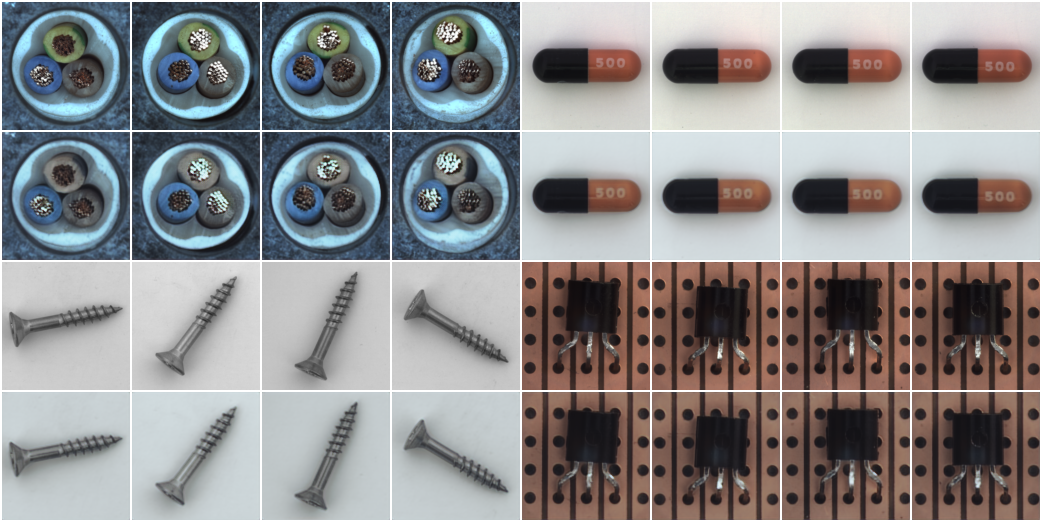

test/reconstructions (19-51-12_u-net-ssim_l1-base)


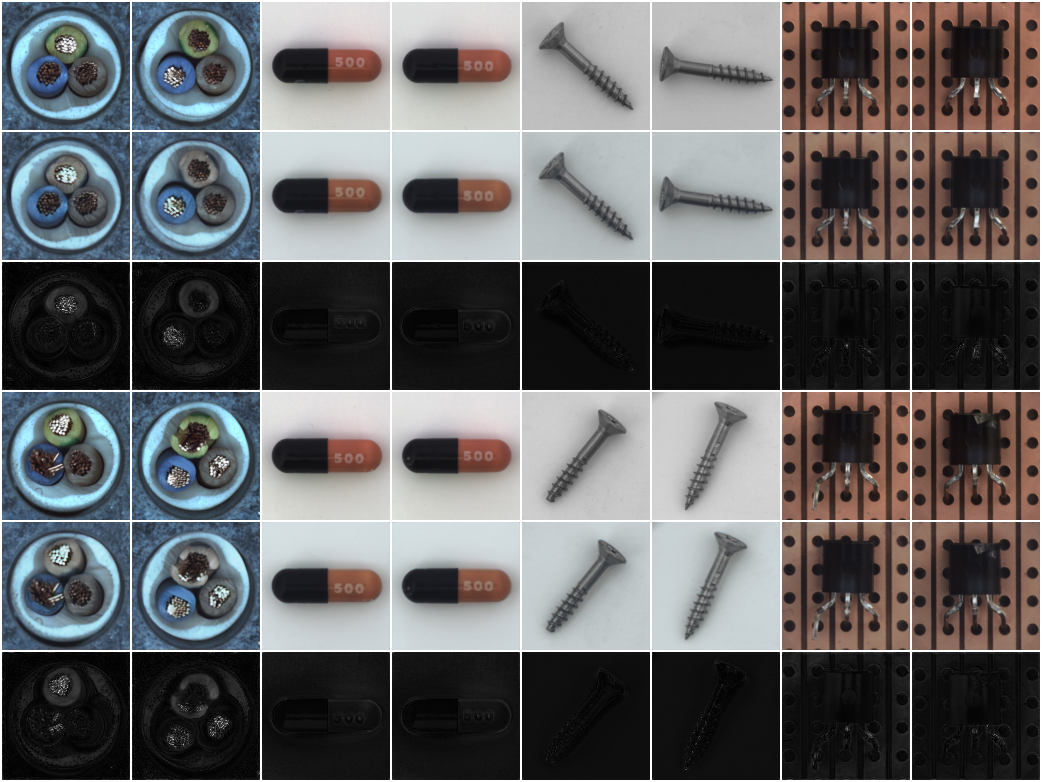

In [16]:
# Verificar las imágenes que W&B guardó en la prueba (deben verse las piezas, no un recuadro negro)
latest = max((ROOT / "outputs").glob("*/*_u-net-ssim_l1*"), key=lambda d: d.stat().st_mtime)
for key in ("val/reconstructions", "test/reconstructions"):
    image = max(latest.glob(f"wandb/*/files/media/images/{key}_*.png"), key=lambda f: f.stat().st_mtime)
    show_image(image, f"{key} ({latest.name})")

### 6.3 Entrenamiento completo: todos los trials con Hydra multirun (sin repetir corridas)
`config.yaml` define el barrido en `hydra.sweeper.params`:

```yaml
hydra:
  sweeper:
    params:
      trial: base,e200_cos,e200_cos_z256
      model: vae,u-net
      loss: l1,l2,ssim,ssim_l1
```

Con `-m`, Hydra ejecuta el producto cartesiano (3 × 2 × 4 = 24 trabajos) **uno tras otro**. `trial` es la primera clave, así que termina las 8 corridas de un trial antes de pasar al siguiente. Equivale a `python train.py -m` en una terminal.

**Corridas ya hechas: se saltan.** Antes de crear la corrida en W&B, `train.py` calcula la **clave del experimento** (`run_key`, en `src/registry.py`). Es un hash de los hiperparámetros que definen la corrida: datos, modelo, pérdida, `Trainer` y semilla. Deja fuera lo que no cambia el resultado: rutas, workers, barra de progreso, modo de W&B y nombres. Después busca:
1. en `outputs/` y `multirun/` un `results.json` con esa clave (solo corridas completas y registradas en W&B online; `results.json` se escribe al final, así que una corrida interrumpida no cuenta);
2. en el proyecto de W&B una corrida **terminada** con esa clave (cubre corridas lanzadas por otro integrante en otra computadora).

Si la encuentra imprime `>> SALTADA <corrida> [clave]: ya existe -> <dónde>` y pasa a la siguiente, sin crear nada en W&B. Las 8 corridas originales (de antes de los trials) tienen la misma clave que el trial `base`, así que ese trial completo se salta. La clave se guarda en `results.json` y en la configuración de cada corrida en W&B. Para forzar un reentrenamiento (por ejemplo, después de cambiar el código de un modelo o una pérdida, que la clave no detecta) se agrega el override `skip_existing.enabled=false`.

**¿Qué pasa al ejecutar las celdas?**
1. La primera muestra el **plan**: cada corrida del barrido, si ya está hecha (y dónde) o pendiente, y el tiempo estimado de las pendientes. No entrena nada.
2. La segunda lanza el barrido. Hydra anuncia cada trabajo (`#0 : trial=base model=vae loss=l1`, ...). Las corridas hechas se saltan en uno o dos segundos (solo crean la carpeta de Hydra) y las pendientes se entrenan en formato compacto: línea de inicio con la clave y el enlace a W&B, una línea cada 5 épocas y un resumen final.
3. Al terminar, la tabla de las corridas entrenadas en esa ejecución.

Cada trabajo es un entrenamiento independiente, con su propia corrida en W&B y su carpeta `multirun/<fecha>/<hora>/<modelo>-<pérdida>-<trial>/` (config, `results.json`, checkpoints `best.ckpt`/`last.ckpt` y archivos de W&B). Si algo falla o se interrumpe, basta con volver a ejecutar la celda: lo terminado se salta y se continúa con lo pendiente.

**Duración estimada (RTX 4060, medida en las corridas `base`):** VAE ≈ 2.5 min y U-Net ≈ 5.7 min por cada 100 épocas con batch 32, o sea ≈ 33 min por cada 8 corridas de 100 épocas. Los dos trials nuevos tienen 200 épocas (≈ 66 min cada uno; con z 256 un poco más), así que las 16 corridas nuevas suman **≈ 2.2 horas**; las 8 de `base` se saltan. Para lanzar solo una parte se agrega un override, por ejemplo `run_train("trial=e200_cos", multirun=True)`.

Recomendaciones antes de ejecutar: equipo conectado a la corriente y sin suspensión automática, y no ejecutar otras celdas mientras corre (el kernel queda ocupado).

In [17]:
# Plan del barrido: qué corridas ya están hechas (se saltarán) y cuáles faltan. No entrena nada.
from src.registry import find_existing, local_runs, run_key, wandb_runs

SWEEP = OmegaConf.load(ROOT / "conf" / "config.yaml").hydra.sweeper.params
MINUTES_PER_100_EPOCHS = {"vae": 2.5, "u-net": 5.7}  # measured in the base runs (batch 32, RTX 4060)


def show_plan(trials=None, models=None, losses=None):
    # One row per run of the sweep, with its run_key and whether it is already done (local or W&B)
    local = local_runs(ROOT)
    try:
        remote = wandb_runs(WANDB_PROJECT, WANDB_ENTITY)
    except Exception as error:  # no connection: only outputs/ and multirun/ are checked
        print("No se pudo consultar W&B, solo se revisa outputs/ y multirun/:", error)
        remote = {}
    rows = []
    for trial in trials or SWEEP.trial.split(","):
        for model in models or SWEEP.model.split(","):
            for loss in losses or SWEEP.loss.split(","):
                c = load_cfg([f"trial={trial}", f"model={model}", f"loss={loss}"])
                done = find_existing(c, ROOT, local=local, remote=remote)
                minutes = MINUTES_PER_100_EPOCHS[model] * c.trainer.max_epochs / 100 * (1.5 if c.data.batch_size < 32 else 1)
                rows.append({"corrida": c.run_name, "clave": run_key(c), "estado": "hecha" if done else "pendiente",
                             "min estimados": 0 if done else round(minutes, 1), "dónde": done or ""})
    table = pd.DataFrame(rows).set_index("corrida")
    pending = table[table.estado == "pendiente"]
    print(f"{len(table)} corridas: {len(table) - len(pending)} hechas (se saltan), {len(pending)} pendientes "
          f"(≈ {pending['min estimados'].sum() / 60:.1f} h) -> W&B {WANDB_ENTITY}/{WANDB_PROJECT}")
    with pd.option_context("display.max_rows", 100, "display.max_colwidth", 120):
        display(table)
    return table


plan = show_plan()

24 corridas: 24 hechas (se saltan), 0 pendientes (≈ 0.0 h) -> W&B danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder


,clave,estado,min estimados,dónde
corrida,,,,
vae-l1-base,22995fee2d3a,hecha,0,local multirun\2026-11-03\15-45-24\vae-l1 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-...
vae-l2-base,4e375f266ee4,hecha,0,local multirun\2026-11-03\15-45-24\vae-l2 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-...
vae-ssim-base,98ddb0541b78,hecha,0,local multirun\2026-11-03\15-45-24\vae-ssim | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-d...
vae-ssim_l1-base,b3804d25845e,hecha,0,local multirun\2026-11-03\15-45-24\vae-ssim_l1 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gic...
u-net-l1-base,b28fca9be1ef,hecha,0,local multirun\2026-11-03\15-45-24\u-net-l1 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-d...
u-net-l2-base,f2fd9953110b,hecha,0,local multirun\2026-11-03\15-45-24\u-net-l2 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-d...
u-net-ssim-base,a647663f5f56,hecha,0,local multirun\2026-11-03\15-45-24\u-net-ssim | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico...
u-net-ssim_l1-base,f06c006333f5,hecha,0,local multirun\2026-11-03\15-45-24\u-net-ssim_l1 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-g...
vae-l1-e200_cos,015cebdca87f,hecha,0,local multirun\2026-11-04\16-33-27\vae-l1-e200_cos | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol...


In [18]:
# ENTRENAMIENTO COMPLETO: todos los trials x 2 modelos x 4 pérdidas (las corridas ya hechas se saltan)
run_train(multirun=True)

$ python train.py -m trainer.enable_progress_bar=false console.verbose=false
[2026-11-04 19:52:40,646][HYDRA] Launching 24 jobs locally
[2026-11-04 19:52:40,646][HYDRA] 	#0 : trial=base model=vae loss=l1 trainer.enable_progress_bar=False console.verbose=False

>> SALTADA vae-l1-base [22995fee2d3a]: ya existe -> local multirun\2026-11-03\15-45-24\vae-l1 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/ic8fvwcj
[2026-11-04 19:52:40,960][HYDRA] 	#1 : trial=base model=vae loss=l2 trainer.enable_progress_bar=False console.verbose=False

>> SALTADA vae-l2-base [4e375f266ee4]: ya existe -> local multirun\2026-11-03\15-45-24\vae-l2 | https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/xbkemfbn
[2026-11-04 19:52:41,465][HYDRA] 	#2 : trial=base model=vae loss=ssim trainer.enable_progress_bar=False console.verbose=False

>> SALTADA vae-ssim-base [98ddb0541b78]: ya existe -> local multirun\2026-11-

### 6.4 Resultados de todas las corridas (locales)
Tabla con el `results.json` de cada corrida completa guardada en esta computadora (la más reciente de cada experimento), para comparar los trials sin esperar a W&B. Las corridas de otros integrantes no aparecen aquí; la comparación completa, desde W&B, está en 9.4. Las pérdidas de entrenamiento y validación solo son comparables **entre trials de la misma combinación modelo/pérdida** (cada pérdida tiene su propia escala); `test L1`, `test SSIM` y los AUROC sí se comparan entre todas.

In [19]:
# Todas las corridas locales completas, agrupadas por modelo/pérdida para comparar sus trials
local_results = pd.DataFrame(local_runs(ROOT).values())
if "trial" not in local_results:  # every run is from before the trials existed
    local_results["trial"] = "base"
local_results["trial"] = local_results["trial"].fillna("base")
local_results = local_results.drop_duplicates(["model", "loss", "trial"])  # newest per combination
columns = [c for c in RESULT_COLUMNS if c in local_results and c != "trial"]
table = (local_results.set_index(["model", "loss", "trial"])[columns].rename(columns=RESULT_COLUMNS)
         .sort_index().round(4))
with pd.option_context("display.max_rows", 100):
    display(table)

minutos  mejor época  train/loss (mejor época)  \
model loss    trial                                                           
u-net l1      base              5.49           82                       NaN   
              e200_cos         10.51          183                    0.0057   
              e200_cos_z256    10.98          179                    0.0058   
      l2      base              5.49           84                       NaN   
              e200_cos         10.44          191                    0.0001   
              e200_cos_z256    11.37          184                    0.0000   
      ssim    base              5.97           96                       NaN   
              e200_cos         11.36          190                    0.0014   
              e200_cos_z256    11.69          200                    0.0015   
      ssim_l1 base              5.99           86                       NaN   
              e200_cos         11.54          176                    0.0020   
              e200_cos_z256    11.72          193                    0.0021   
vae   l1      base              2.66           91                       NaN   
              e200_cos          4.14          199                    0.0431   
              e200_cos_z256     4.23          176                    0.0463   
      l2      base              1.95           95                       NaN   
              e200_cos          3.47          173                    0.0099   
              e200_cos_z256     4.17          176                    0.0103   
      ssim    base              2.63          100                       NaN   
              e200_cos          4.46          184                    0.1271   
              e200_cos_z256     5.65          186                    0.1384   
      ssim_l1 base              2.59           94                       NaN   
              e200_cos          4.86          200                    0.1211   
              e200_cos_z256     5.69          199                    0.1279   

                             mejor val/loss  test L1  test SSIM  AUROC L1  \
model loss    trial                                                         
u-net l1      base                   0.0065   0.0064     0.9912    0.4014   
              e200_cos               0.0035   0.0036     0.9954    0.5080   
              e200_cos_z256          0.0033   0.0034     0.9958    0.5155   
      l2      base                   0.0001   0.0051     0.9927    0.3501   
              e200_cos               0.0000   0.0035     0.9955    0.4370   
              e200_cos_z256          0.0000   0.0034     0.9958    0.3816   
      ssim    base                   0.0016   0.0042     0.9984    0.5941   
              e200_cos               0.0010   0.0026     0.9989    0.6467   
              e200_cos_z256          0.0012   0.0034     0.9988    0.5537   
      ssim_l1 base                   0.0023   0.0044     0.9980    0.6493   
              e200_cos               0.0014   0.0022     0.9987    0.4443   
              e200_cos_z256          0.0015   0.0024     0.9987    0.3949   
vae   l1      base                   0.0451   0.0403     0.7860    0.4979   
              e200_cos               0.0387   0.0359     0.8003    0.5464   
              e200_cos_z256          0.0408   0.0375     0.7931    0.5911   
      l2      base                   0.0106   0.0566     0.7375    0.4922   
              e200_cos               0.0089   0.0506     0.7506    0.5096   
              e200_cos_z256          0.0090   0.0519     0.7490    0.4823   
      ssim    base                   0.1671   0.0420     0.8359    0.5072   
              e200_cos               0.1610   0.0403     0.8394    0.4978   
              e200_cos_z256          0.1584   0.0406     0.8407    0.5023   
      ssim_l1 base                   0.1531   0.0401     0.8321    0.4810   
              e200_cos               0.1438   0.0383     0.8383    0.5032   
              e200_cos_z256          0.1420   0.0

## 7. Seguimiento de los entrenamientos en W&B
Todas las corridas se registraron en W&B durante el entrenamiento (callbacks de `src/callbacks.py`). En esta sección y la siguiente se recuperan con la API de W&B (`src/wandb_utils.py`) y se muestran aquí. Las figuras nuevas que se construyen a partir de esos datos (curvas combinadas, cuadrículas de t-SNE, histogramas, comparaciones) se registran también en una corrida de análisis (`notebook-analysis-<trial>`, `job_type = analysis`) antes de mostrarse.

| Requisito de la tarea | Clave en W&B | Sección |
|---|---|---|
| Pérdida de entrenamiento y validación | `train/loss`, `val/loss` (+ `val/l1`, `val/mse`, `val/ssim`) | 7.1 |
| Originales vs reconstrucciones del set de validación (16) | `val/reconstructions` | 7.2 |
| Vector latente con t-SNE (validación) a lo largo de las épocas | `val/tsne` | 7.3 |
| Reconstrucción de imágenes buenas y con anomalías del set de prueba (16) | `test/reconstructions` | 8.1 |
| Histogramas del error, normales vs cada subclase de defecto | `test/scores` | 8.2 |
| Comparación entre configuraciones (funciones de pérdida) | `test/*` del resumen de cada corrida | 9 |

**Trial analizado.** Las secciones 7 y 8 analizan las 8 corridas (2 modelos × 4 pérdidas) de **un** trial, el de `TRIAL`. Se usa `e200_cos` (200 épocas, lr coseno), que fue el mejor de los tres. Mejora la reconstrucción de prueba de las **8** combinaciones respecto a `base` y sube el AUROC medio de ambos modelos, mientras que agrandar el latente a 256 (`e200_cos_z256`) no agregó mejoras consistentes. La tabla de la celda siguiente lo resume por trial y la sección 9.4 lo detalla por combinación.

In [20]:
# Corridas de W&B: todas (para comparar trials) y las 8 del trial analizado
import numpy as np
import plotly.express as px

from src import wandb_utils as wu

CLASSES = list(cfg.data.classes)
TRIAL = "e200_cos"  # trial analysed in sections 7-9 (best of the three, see the table below and 9.4)

all_runs = wu.get_all_runs(WANDB_PROJECT, WANDB_ENTITY)  # every finished training run, newest per (model, loss, trial)
runs = wu.get_runs(WANDB_PROJECT, WANDB_ENTITY, trial=TRIAL, all_runs=all_runs)
assert len(runs) == 8, f"Se esperaban 8 corridas terminadas del trial {TRIAL}, hay {len(runs)}"

print(f"{len(all_runs)} corridas de entrenamiento en W&B. Trial analizado: {TRIAL}")
for row in wu.summary_table(runs, []):
    print(f"  {row['model']:<6} {row['loss']:<8} {row['run']:<24} {runs[(row['model'], row['loss'])].url}")

# Mean of the 8 runs of each trial, per model (higher SSIM / AUROC and lower L1 are better)
trial_keys = {"test/l1": "test L1", "test/ssim": "test SSIM", "test/auroc_ssim_mean": "AUROC 1-SSIM",
              "test/auroc_max_mean": "AUROC máx"}
by_trial = (pd.DataFrame(wu.trials_table(all_runs, list(trial_keys)))
            .groupby(["trial", "model"])[list(trial_keys)].mean().rename(columns=trial_keys).unstack("model"))
display(by_trial.round(4))

analysis_run = start_notebook_run(f"notebook-analysis-{TRIAL}")

24 corridas de entrenamiento en W&B. Trial analizado: e200_cos
  vae    l1       vae-l1-e200_cos          https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/gk7ydhue
  vae    l2       vae-l2-e200_cos          https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/4xg23j2b
  vae    ssim     vae-ssim-e200_cos        https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/85zwaegk
  vae    ssim_l1  vae-ssim_l1-e200_cos     https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/z795z7ft
  u-net  l1       u-net-l1-e200_cos        https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/zcqtwdei
  u-net  l2       u-net-l2-e200_cos        https://forge.coreweave.com/wandb/danielpulido-instituto-tecnol-gico-de-costa-rica/Autoencoder/runs/4zobrdey
  u-net  ssim     u-net-s

test L1         test SSIM         AUROC 1-SSIM          \
model           u-net     vae     u-net     vae        u-net     vae   
trial                                                                  
base           0.0051  0.0447    0.9951  0.7979       0.3196  0.6277   
e200_cos       0.0030  0.0413    0.9971  0.8071       0.3342  0.6336   
e200_cos_z256  0.0032  0.0421    0.9973  0.8057       0.3358  0.6381   

              AUROC máx          
model             u-net     vae  
trial                            
base             0.4761  0.5861  
e200_cos         0.5594  0.6142  
e200_cos_z256    0.5296  0.6093

### 7.1 Pérdida de entrenamiento y validación
La primera figura muestra, para cada función de pérdida, su `train/loss` (línea continua) y `val/loss` (discontinua) en escala logarítmica. Cada pérdida tiene su propia escala (SSIM ≈ 0.1, L2 ≈ 0.0001), así que esta figura sirve para ver **convergencia y sobreajuste** dentro de cada corrida, no para decidir qué pérdida es mejor. Para eso, la segunda figura compara las métricas comunes `val/l1`, `val/mse` y `val/ssim`, que se calculan igual en todas las corridas.

In [ ]:
# Pérdida de entrenamiento y validación de cada corrida (una figura por modelo)
for model in wu.MODELS:
    log_and_zshow(analysis_run, f"curves/{model}_train_val_loss", fig=wu.train_val_figure(runs, model))

In [22]:
# Métricas comunes de validación (misma escala para las 4 pérdidas)
for model in wu.MODELS:
    log_and_show(analysis_run, f"curves/{model}_common_metrics", fig=wu.loss_curves_figure(runs, model))

**Análisis.**
- **No hay sobreajuste.** En las 8 corridas `train/loss` y `val/loss` bajan juntas, y `val/loss` nunca vuelve a subir.
  - En 6 corridas la validación termina igual o por debajo del entrenamiento (por ejemplo, `u-net-l1`: 0.0054 en train y 0.0039 en val). Es esperable: en entrenamiento el VAE muestrea $z$ con ruido y BatchNorm usa estadísticas del lote, mientras que en validación se usa $z = \mu$ y las estadísticas acumuladas; además, la pérdida de entrenamiento se promedia mientras los pesos todavía mejoran durante la época.
  - En el VAE con SSIM y SSIM+L1, la validación queda ≈ 0.02–0.03 por encima (`vae-ssim_l1`: 0.121 en train y 0.144 en val), pero sigue bajando hasta la última época. Es una pequeña brecha de generalización, no sobreajuste.
- **La U-Net converge mucho más rápido.** En la época 20 ya tiene `val_ssim` ≈ 0.98–0.996, y termina en 0.995–0.999. El VAE en la época 20 está en 0.70–0.79 y sigue mejorando casi hasta el final: 0.824 (L1), 0.763 (L2), 0.868 (SSIM) y 0.867 (SSIM+L1).
- **El lr coseno estabiliza el final.** Con el lr alto del inicio hay saltos (por ejemplo, la `val/loss` de `u-net-ssim` pasa de 0.0037 en la época 20 a 0.0079 en la 50). A medida que el lr baja, las curvas se aplanan y entre las épocas 180 y 200 casi no cambian, sin la oscilación final del trial `base`.
- **Entre pérdidas (métricas comunes):** en el VAE, las pérdidas basadas en SSIM logran el mejor `val/ssim` (≈ 0.87) y L2 el peor (0.76). L2 castiga poco los errores pequeños y repartidos, así que favorece reconstrucciones promedio y borrosas. En la U-Net las cuatro pérdidas quedan prácticamente en el techo.

### 7.2 Reconstrucciones del set de validación (16 imágenes)
`ReconstructionCallback` registra cada 5 épocas las mismas 16 imágenes de validación (4 por clase): las filas impares son las originales y las pares, sus reconstrucciones. Primero se muestra la época 1 de cada modelo como referencia del punto de partida y después la última época de las 8 corridas.

vae / l1 - época 1 (referencia)


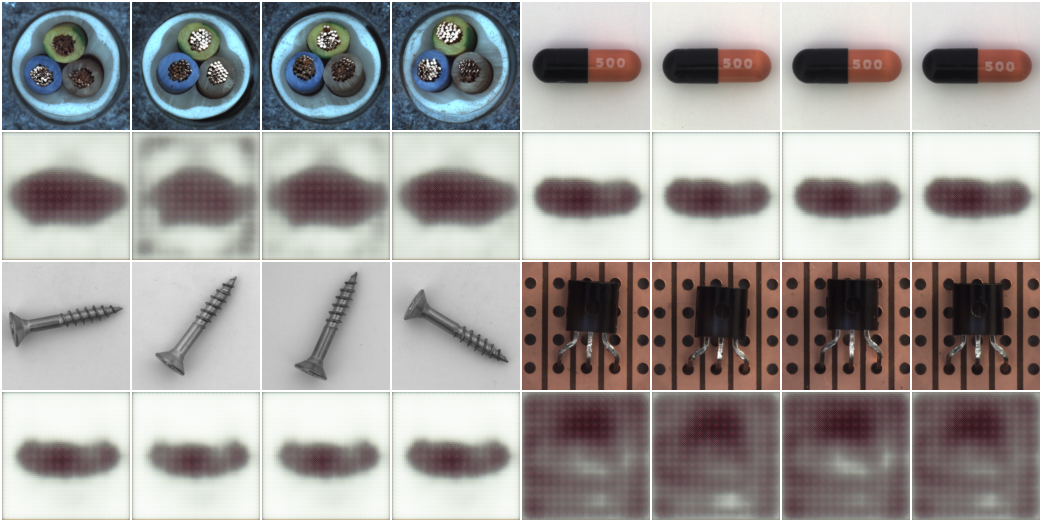

vae / l1 - época 200


ValueError: Cannot embed the 'none' image format

In [23]:
# Reconstrucciones de validación: época 1 (referencia) y última época de cada corrida
max_epochs = runs[("vae", "l1")].config["trainer"]["max_epochs"]
for model in wu.MODELS:
    show_image(wu.first_image(runs[(model, "l1")], "val/reconstructions"), f"{model} / l1 - época 1 (referencia)")
    for loss in wu.LOSSES:
        show_image(wu.last_image(runs[(model, loss)], "val/reconstructions"), f"{model} / {loss} - época {max_epochs}")

**Análisis.**
- **Época 1:** ambos modelos devuelven manchas grises casi iguales para todas las imágenes, con apenas una silueta.
- **VAE:** reconstruye la forma y el color general de cada objeto, pero borroso. Los detalles finos se pierden: los hilos de cobre del cable, la rosca del tornillo, el texto "500" de la cápsula y las patas del transistor. Toda la imagen pasa por un vector de 128 valores, así que el decoder solo puede generar una versión "promedio" de cada objeto.
  - **L2:** es la más borrosa; el tornillo queda como una mancha.
  - **L1:** es algo más nítida y respeta los colores.
  - **SSIM y SSIM+L1:** son las más nítidas en bordes y estructura, pero pueden equivocarse de color (por ejemplo, los núcleos del cable), porque SSIM compara estructura y contraste locales más que el color exacto.
- **U-Net:** sus reconstrucciones son casi indistinguibles de la entrada con las cuatro pérdidas. Las *skip connections* llevan los detalles de alta resolución directamente del encoder al decoder sin pasar por el cuello de botella.
- **Por clase:** la cápsula es la clase más fácil (siempre en la misma posición). El tornillo es la más difícil para el VAE porque aparece con cualquier rotación, y a veces se reconstruye con un ángulo distinto al real.

### 7.3 Espacio latente con t-SNE (validación, a lo largo de las épocas)
`LatentTSNECallback` proyecta con t-SNE el vector latente $z$ de las 147 imágenes de validación cada 10 épocas, con un color por clase. En el VAE, $z = \mu$; en la U-Net, $z$ es el promedio espacial del cuello de botella. Primero se muestra la evolución de una corrida por modelo en 6 momentos del entrenamiento y después la última época de las 8 corridas. Las cuadrículas se arman con las figuras registradas por el callback y se registran en W&B.

In [24]:
# Evolución del t-SNE de validación: 6 momentos del entrenamiento de una corrida por modelo
TSNE_LOSS = "ssim_l1"  # loss of the runs whose evolution is shown
for model in wu.MODELS:
    history = [fig for _, fig in wu.plotly_history(runs[(model, TSNE_LOSS)], "val/tsne")]
    picks = [history[round(i * (len(history) - 1) / 5)] for i in range(6)]  # evenly spaced, first and last included
    fig = wu.tsne_grid(picks, [f"época {wu.tsne_epoch(f)}" for f in picks], cols=6,
                       title=f"{model} / {TSNE_LOSS}: t-SNE del latente (validación) a lo largo del entrenamiento")
    log_and_show(analysis_run, f"tsne/{model}_{TSNE_LOSS}_evolution", fig=fig)

In [ ]:
# t-SNE de validación en la última época de las 8 corridas
figs = [wu.last_plotly(runs[(model, loss)], "val/tsne") for model in wu.MODELS for loss in wu.LOSSES]
titles = [f"{model} / {loss}" for model in wu.MODELS for loss in wu.LOSSES]
fig = wu.tsne_grid(figs, titles, cols=4, title=f"t-SNE del latente (validación), última época - trial {TRIAL}")
log_and_show(analysis_run, "tsne/val_last_epoch", fig=fig)

**Análisis.**
- **Desde la época 1 las 4 clases forman grupos casi separados** en ambos modelos. Son objetos muy distintos en color, brillo y forma, así que incluso un encoder casi sin entrenar los distingue. Lo interesante es cómo cambia la estructura **dentro** de cada clase.
- **VAE:** a medida que entrena, el latente pasa de 4 puntos compactos a representar la variación de cada objeto. Con L2, el tornillo forma un **anillo**: el VAE aprendió a codificar de forma continua el ángulo de rotación, que es lo que más varía entre tornillos. Con las pérdidas SSIM, cable y tornillo se abren en "rayos" alrededor del centro, mientras que la cápsula, que casi no varía, sigue compacta. El término KL empuja a $q(z|x)$ hacia $\mathcal{N}(0, I)$, por eso los grupos quedan más cerca entre sí y repartidos alrededor del origen que en la U-Net.
- **U-Net:** los 4 grupos quedan compactos y bien separados durante todo el entrenamiento. Su $z$ es solo el promedio del cuello de botella, sin regularización, y el detalle de la imagen viaja por las *skip connections*, así que $z$ no necesita codificar la variación dentro de cada clase.

## 8. Evaluación del modelo
La evaluación usa el set de prueba completo (542 imágenes: 182 buenas y 360 con defectos) con el **mejor checkpoint** de cada corrida (menor `val/loss`). La idea de la detección de anomalías por reconstrucción es que el modelo solo vio imágenes buenas: debería reconstruirlas bien y fallar en las zonas con defectos, así que el **error de reconstrucción de cada imagen funciona como puntaje de anomalía**.

`test/scores` guarda cuatro errores por imagen:
- `score_l1` / `score_mse`: error absoluto / cuadrático medio de toda la imagen;
- `score_ssim`: $1 - \mathrm{SSIM}(x, \hat{x})$ (error estructural);
- `score_max`: máximo del mapa de error $|x - \hat{x}|$ suavizado con una ventana de 11x11. El promedio de toda la imagen diluye un defecto pequeño (un rayón cubre menos del 1 % de los píxeles); el máximo local no.

La calidad de un puntaje como detector se mide con el **AUROC**: la probabilidad de que una imagen defectuosa elegida al azar tenga más error que una buena (0.5 = azar, 1 = perfecto, < 0.5 = invertido). Se calcula por clase y se promedia, como en MVTec AD.

### 8.1 Reconstrucción de imágenes buenas y con anomalías (16 imágenes de prueba)
`TestReconstructionCallback` registra 8 imágenes buenas y 8 defectuosas del set de prueba (2 por clase, en el orden cable, cable, cápsula, cápsula, tornillo, tornillo, transistor, transistor), siempre las mismas en todas las corridas. Las filas 1-3 son las buenas y las filas 4-6 las defectuosas; en cada grupo van la original, la reconstrucción y el mapa de error $|x - \hat{x}|$, con una misma escala para ambas mitades. **Lo esperado**: reconstrucciones fieles y mapa oscuro en las buenas, y error concentrado en el defecto en las defectuosas.

In [ ]:
# Reconstrucciones del set de prueba: 8 buenas (filas 1-3) y 8 con defectos (filas 4-6)
for model in wu.MODELS:
    for loss in wu.LOSSES:
        show_image(wu.last_image(runs[(model, loss)], "test/reconstructions"), f"{model} / {loss} - set de prueba")

**Análisis.**
- **U-Net:** reconstruye las imágenes defectuosas **con el defecto incluido** (el cable con hilos fuera de lugar, el transistor dañado). El mapa de error queda igual de oscuro en las buenas que en las defectuosas, es decir, la U-Net aprendió algo muy cercano a la función identidad: las *skip connections* le permiten copiar cualquier imagen, normal o no. Es el mejor modelo para **reconstruir** y el peor para **detectar**.
- **VAE:** por el cuello de botella, tiende a reconstruir la versión "normal" del objeto. En los defectos grandes la diferencia se ve en el mapa de error, por ejemplo en el transistor con la carcasa dañada o en el cable con los hilos cruzados. Pero el mapa **también se ilumina en las imágenes buenas**, en todas las texturas finas que el VAE no puede reproducir (hilos de cobre, rosca del tornillo, bordes de las patas). Ese "ruido de fondo" compite con el error del defecto y es la razón principal por la que los defectos pequeños no se distinguen (ver 8.2).
- Entre pérdidas del VAE, L2 da el error de fondo más alto (reconstrucción más borrosa) y las pérdidas SSIM el más bajo.

In [ ]:
# t-SNE del set de prueba (verde = good, rojo = defectuosa; el símbolo indica la clase)
figs = [wu.last_plotly(runs[(model, loss)], "test/tsne") for model in wu.MODELS for loss in wu.LOSSES]
titles = [f"{model} / {loss}" for model in wu.MODELS for loss in wu.LOSSES]
fig = wu.tsne_grid(figs, titles, cols=4, title=f"t-SNE del latente (prueba): good vs defectuosas - trial {TRIAL}")
log_and_show(analysis_run, "tsne/test_good_vs_defective", fig=fig)

En el t-SNE del set de prueba, las imágenes buenas (verde) y defectuosas (rojo) de cada clase quedan **mezcladas** en el mismo grupo en todas las corridas. El vector latente codifica *qué* objeto es y su pose, no si tiene un defecto. Por eso la detección se hace con el error de reconstrucción y no con el latente. La excepción es el tornillo en la U-Net, donde las defectuosas sí se agrupan aparte de las buenas; como se ve en 8.3, eso se debe a una diferencia de iluminación del dataset, no al defecto.

### 8.2 Histogramas del error de reconstrucción por subclase de defecto
Con la tabla `test/scores` se grafica, para cada clase, el error de las imágenes **buenas** (verde) contra el de **cada tipo de defecto** (rojo). Los histogramas están normalizados (la cantidad de imágenes buenas y de cada defecto es distinta) y usan los mismos intervalos; cuanto menos se solapan, mejor se detecta ese defecto. El título de cada panel incluye su AUROC.

Se usa `SCORE = "score_ssim"` (1 − SSIM), el mejor puntaje para el VAE (AUROC medio 0.69 con SSIM+L1, contra 0.50 de `score_l1`) y además poco sensible al brillo global de la imagen (ver 8.3). Se grafica la mejor corrida de cada modelo según ese puntaje; cambiando `SCORE` o `HIST_RUNS` se pueden ver las demás.

In [ ]:
# Tablas de errores por imagen (test/scores) de las 8 corridas y corridas para los histogramas
SCORE = "score_ssim"  # score_l1 | score_mse | score_ssim | score_max
auroc_key = "test/auroc_" + SCORE.removeprefix("score_")

scores = {key: wu.load_table(run) for key, run in runs.items()}  # used again in section 9
best = {model: max(wu.LOSSES, key=lambda l: runs[(model, l)].summary.get(f"{auroc_key}_mean", 0)) for model in wu.MODELS}
HIST_RUNS = list(best.items())
print("Corridas para los histogramas:",
      ", ".join(f"{m} / {l} (AUROC medio {runs[(m, l)].summary[f'{auroc_key}_mean']:.3f})" for m, l in HIST_RUNS))

In [ ]:
# Histogramas del error: imágenes buenas vs cada tipo de defecto, por clase
for model, loss in HIST_RUNS:
    for category in CLASSES:
        fig = wu.error_histograms(scores[(model, loss)], category, SCORE, title_prefix=f"{model} / {loss} - ")
        log_and_show(analysis_run, f"histograms/{model}_{loss}/{category}", fig=fig)

Los histogramas anteriores son solo de 2 corridas. Para comparar **todas las configuraciones en cada subclase de defecto**, la tabla siguiente resume cada par (buenas, defecto) con su AUROC, en una fila por defecto y una columna por corrida.

In [ ]:
# AUROC de cada subclase de defecto en las 8 corridas
rows = [{"model": m, "loss": l, **d} for (m, l), table in scores.items() for d in wu.defect_table(table, SCORE)]
defects = pd.DataFrame(rows)
analysis_run.log({f"comparison/defect_auroc_{SCORE}": wandb.Table(dataframe=defects)})

pivot = defects.pivot_table(index=["category", "defect", "n"], columns=["model", "loss"], values="auroc")
pivot = pivot[[(m, l) for m in wu.MODELS for l in wu.LOSSES]]
fig = px.imshow(pivot.values, x=[f"{m} / {l}" for m, l in pivot.columns], y=[f"{c} / {d} (n={n})" for c, d, n in pivot.index],
                color_continuous_scale="RdYlGn", zmin=0, zmax=1, text_auto=".2f", aspect="auto",
                title=f"AUROC por subclase de defecto ({wu.SCORE_NAMES[SCORE]}) - trial {TRIAL}")
fig.update_layout(height=750, template="plotly_white")
log_and_show(analysis_run, f"comparison/defect_auroc_heatmap_{SCORE}", fig=fig)

**Análisis** (con `score_ssim`, trial `e200_cos`).
- **Defectos grandes o que cambian la forma: el VAE los detecta bien.** En las corridas SSIM / SSIM+L1 del VAE:
  - transistor: `misplaced` 1.00, `bent_lead` ≈ 0.89, `cut_lead` ≈ 0.80, `damaged_case` ≈ 0.77;
  - cápsula: `squeeze` ≈ 0.94;
  - cable: `cut_inner_insulation` y `cut_outer_insulation` ≈ 0.95, `missing_cable` ≈ 0.95, `combined` ≈ 0.83 y `cable_swap` ≈ 0.80.

  En los histogramas, las barras rojas de estos defectos quedan claramente a la derecha de las verdes: el VAE "corrige" el objeto hacia su forma normal y el error se dispara.
- **Defectos pequeños o de textura: cerca del azar o por debajo.** En la cápsula, `crack` (≈ 0.57), `scratch` (≈ 0.56), `faulty_imprint` (≈ 0.47) y `poke` (≈ 0.40); en el cable, `poke_insulation` (≈ 0.53) y `missing_wire` (≈ 0.50). Estos defectos ocupan unos pocos píxeles a 128x128, y su error es menor que el error de fondo que el VAE comete en las texturas de cualquier imagen buena, así que los histogramas se superponen.
- **La U-Net queda en ≈ 0.2–0.6 en casi todos los defectos**, incluso en los grandes (`misplaced` 0.46–0.64, `squeeze` 0.35–0.50), porque copia el defecto y no deja error. Su única detección clara es `cut_outer_insulation` con las pérdidas SSIM (≈ 0.78).
- **Tornillo:** con el VAE entrenado con SSIM queda en ≈ 0.4–0.66, y con la U-Net en **≈ 0.00** en todos sus defectos. Un AUROC de 0 significa que las imágenes buenas tienen *más* error que las defectuosas, algo que el defecto no explica; se analiza en 8.3.

### 8.3 El caso del tornillo: cambio de iluminación entre entrenamiento y prueba
El AUROC del tornillo es extremo y contradictorio. Con `score_l1` va de 1.00 (`u-net-ssim`) a 0.00 (`vae-ssim`), y con 1 − SSIM la U-Net da 0.00 en los 5 tipos de defecto. Un detector real no se comporta así, y la causa está en el dataset: las imágenes **buenas del set de prueba** de `screw` están tomadas con una iluminación más oscura que las de entrenamiento y que las defectuosas. La celda siguiente mide el brillo medio de cada grupo directamente en las imágenes.

In [ ]:
# Brillo medio (0-255, escala de grises) de las imágenes de cada clase por grupo: train/good, test/good y test con defecto
from PIL import Image as PILImage

data_root = ROOT / cfg.data.root
rows = []
for category in CLASSES:
    groups = {"train/good": [data_root / category / "train" / "good"],
              "test/good": [data_root / category / "test" / "good"],
              "test/defectos": [d for d in (data_root / category / "test").iterdir() if d.name != "good"]}
    row = {"clase": category}
    for name, folders in groups.items():
        files = [f for folder in folders for f in sorted(folder.glob("*.png"))]
        row[name] = np.mean([np.asarray(PILImage.open(f).convert("L").resize((cfg.data.img_size,) * 2)).mean() for f in files])
    rows.append(row)
brightness = pd.DataFrame(rows).set_index("clase")
analysis_run.log({"dataset/brightness": wandb.Table(dataframe=brightness.reset_index())})
display(brightness.round(1))

**Análisis.** En `cable`, `capsule` y `transistor` los tres grupos tienen prácticamente el mismo brillo, mientras que en `screw` las imágenes buenas de prueba son claramente más oscuras (≈ 170) que las de entrenamiento (≈ 184) y que las defectuosas (≈ 187). Los modelos solo vieron tornillos "claros", así que la diferencia entre imágenes buenas y defectuosas de prueba que más pesa en el error es el brillo, no el defecto:
- en el VAE, el error L1 de las imágenes **buenas** de prueba (más oscuras de lo que el modelo aprendió) es mayor que el de las defectuosas, y el AUROC sale invertido (0.00–0.12 según la pérdida);
- en la U-Net, el resultado depende de cómo cada pérdida trata la intensidad: con `score_l1` va de 0.11 (L2) a 1.00 (SSIM), y con 1 − SSIM es ≈ 0.00 en las cuatro. En el t-SNE de prueba (8.1), los tornillos buenos y defectuosos de la U-Net forman grupos separados por la misma razón.

En todos los casos el puntaje mide **la iluminación y no el defecto**, así que los resultados del tornillo no son confiables para comparar modelos. Con 1 − SSIM, que es menos sensible al brillo absoluto, el VAE entrenado con SSIM queda en ≈ 0.4–0.66: a 128x128, los rayones y defectos de rosca prácticamente no se distinguen. Por esto la sección 9 incluye también el AUROC medio **sin** el tornillo.

## 9. Comparación entre configuraciones
### 9.1 Funciones de pérdida: reconstrucción y detección
Resumen de las 8 corridas del trial analizado, con métricas que se calculan igual en todas:
- **Entrenamiento / validación:** `train/loss` y `val/loss` de la última época (cada una en la escala de su propia pérdida, comparables solo entre corridas con la misma pérdida); `val/l1` y `val/ssim` en escala común.
- **Prueba, reconstrucción:** `test/l1` y `test/ssim` sobre las 542 imágenes de prueba con el mejor checkpoint.
- **Prueba, detección:** AUROC medio por clase con los tres puntajes, y el mismo promedio **sin el tornillo** (por lo visto en 8.3).

In [ ]:
# Tabla comparativa de las 8 corridas
keys = ["train/loss", "val/loss", "val/l1", "val/ssim", "test/l1", "test/ssim",
        "test/auroc_l1_mean", "test/auroc_ssim_mean", "test/auroc_max_mean"]
comparison = pd.DataFrame(wu.summary_table(runs, keys)).set_index(["model", "loss"]).drop(columns="run")
for short in ("ssim", "max"):  # mean per-class AUROC without screw (illumination shift, see 8.3)
    comparison[f"auroc_{short} sin screw"] = [
        np.mean([runs[key].summary[f"test/auroc_{short}/{c}"] for c in CLASSES if c != "screw"]) for key in comparison.index]
analysis_run.log({"comparison/summary": wandb.Table(dataframe=comparison.reset_index())})
display(comparison.round(4))

In [ ]:
# AUROC por clase de cada modelo y pérdida
per_class = pd.DataFrame(wu.summary_table(runs, [f"{auroc_key}/{c}" for c in CLASSES])).drop(columns="run")
per_class = per_class.melt(id_vars=["model", "loss"], var_name="clase", value_name="auroc")
per_class["clase"] = per_class["clase"].str.split("/").str[-1]

fig = px.bar(per_class, x="clase", y="auroc", color="loss", barmode="group", facet_col="model",
             color_discrete_map=wu.LOSS_COLORS, template="plotly_white", range_y=[0, 1],
             title=f"AUROC por clase ({wu.SCORE_NAMES[SCORE]}) - trial {TRIAL}")
fig.add_hline(y=0.5, line_dash="dot")
log_and_show(analysis_run, "comparison/auroc_per_class", fig=fig)

**Análisis.**
- **Reconstrucción:** la U-Net supera al VAE por mucho con cualquier pérdida (`test/ssim` ≈ 0.995–0.999 frente a 0.75–0.84; `test/l1` ≈ 0.002–0.004 frente a 0.036–0.051). En la U-Net, SSIM+L1 y SSIM dan el menor error L1 y el mayor SSIM. En el VAE, el mejor SSIM es el de SSIM+L1 y SSIM (≈ 0.84), y el mejor L1 el de L1 (0.036), con SSIM+L1 casi igual (0.038). L2 es la peor en ambas métricas (SSIM 0.75, L1 0.051): optimizar el error cuadrático produce reconstrucciones promedio y borrosas.
- **Detección:** la relación se invierte. El VAE con **SSIM+L1** es la mejor configuración: AUROC medio 0.69 con 1 − SSIM y ≈ 0.74 sin el tornillo, con transistor 0.87 y cable 0.78. Le sigue el VAE con SSIM. La U-Net queda por debajo de 0.5 con 1 − SSIM en casi todas las clases, porque reconstruye también los defectos.
- **Pérdida y puntaje:** con las pérdidas SSIM el VAE aprende a reproducir la *estructura* de las piezas buenas, y por eso el error estructural (1 − SSIM) es el que mejor separa los defectos que cambian la forma. Con L1/L2 la reconstrucción respeta mejor el color, pero el error se reparte en toda la textura y separa peor.
- La clase más fácil es el transistor (los defectos cambian la geometría: pata doblada, cortada o pieza desplazada) y la más difícil la cápsula (defectos diminutos sobre una superficie lisa).

### 9.2 Reconstrucción de imágenes correctas vs defectuosas
Error medio de reconstrucción (`SCORE`) de las imágenes buenas y de las defectuosas por clase, y la **razón defectuosas / buenas**. Un modelo que detecta anomalías reconstruye bien lo normal y mal lo anómalo: razón claramente mayor que 1. Una razón ≈ 1 indica que reconstruye igual de bien (o de mal) ambas.

In [ ]:
# Error medio good vs defectuosas por configuración y clase
rows = []
for (model, loss), table in scores.items():
    for category, (mean_good, mean_bad) in wu.good_vs_defective_means(table, SCORE).items():
        rows.append({"model": model, "loss": loss, "clase": category,
                     "error good": mean_good, "error defectuosas": mean_bad, "razón def/good": mean_bad / mean_good})
errors = pd.DataFrame(rows)
analysis_run.log({"comparison/good_vs_defective": wandb.Table(dataframe=errors)})

ratio = errors.pivot_table(index=["model", "loss"], columns="clase", values="razón def/good")
ratio = ratio.loc[[(m, l) for m in wu.MODELS for l in wu.LOSSES], CLASSES + ["all"]]
display(ratio.round(2))

long = errors.melt(id_vars=["model", "loss", "clase"], value_vars=["error good", "error defectuosas"],
                   var_name="tipo", value_name="error")
fig = px.bar(long[long.clase != "all"], x="loss", y="error", color="tipo", barmode="group",
             facet_row="model", facet_col="clase", template="plotly_white", height=600,
             color_discrete_map={"error good": "#2ca02c", "error defectuosas": "#d62728"},
             title=f"Error medio de reconstrucción ({wu.SCORE_NAMES[SCORE]}): imágenes buenas vs defectuosas")
fig.update_yaxes(matches=None)  # each model has its own error scale
log_and_show(analysis_run, "comparison/good_vs_defective", fig=fig)

**Análisis.**
- **U-Net:** en cable, cápsula y transistor la razón es ≈ 0.94–1.01 con las cuatro pérdidas: reconstruye las imágenes defectuosas tan bien como las buenas. En el tornillo baja a 0.47–0.80 por la iluminación (8.3). Su error absoluto es mucho menor que el del VAE en ambos grupos.
- **VAE:** en cable, cápsula y transistor las defectuosas siempre tienen más error que las buenas.
  - Transistor: la diferencia es la mayor, unas **2.1 veces** con SSIM y SSIM+L1 y 1.7 con L1, porque sus defectos cambian la forma de la pieza.
  - Cápsula: ≈ 1.1–1.2.
  - Cable: ≈ 1.04–1.14.
  - L2 da las razones más bajas (transistor 1.26), consistente con su reconstrucción más borrosa: el error de fondo de las buenas es más alto.
  - Tornillo: ≈ 1, el defecto no se distingue.
- **Error global:** si se mira solo la columna `all`, el VAE parece no distinguir nada (razón 0.81–0.99). Mezclar clases con escalas de error distintas oculta la separación que sí hay dentro de cada clase. Por eso el AUROC se calcula por clase.

### 9.3 Mejor configuración por objetivo

In [ ]:
# Mejor configuración (modelo / pérdida) según el objetivo
goals = {"reconstrucción (test SSIM)": ("test/ssim", max), "reconstrucción (test L1)": ("test/l1", min),
         "detección (AUROC 1-SSIM)": ("test/auroc_ssim_mean", max), "detección (AUROC máx)": ("test/auroc_max_mean", max)}
best_rows = []
for goal, (key, pick) in goals.items():
    model, loss = pick(runs, key=lambda k: runs[k].summary[key])
    best_rows.append({"objetivo": goal, "modelo": model, "pérdida": loss, "valor": runs[(model, loss)].summary[key]})
display(pd.DataFrame(best_rows).set_index("objetivo").round(4))

Reconstruir bien y detectar bien **no coinciden**. La mejor reconstrucción la logra la U-Net (con SSIM o SSIM+L1); la mejor detección, el VAE con SSIM+L1. Para detectar anomalías por reconstrucción, el modelo tiene que ser *incapaz* de reconstruir lo que no vio en entrenamiento, y las *skip connections* de la U-Net eliminan justamente esa limitación.

### 9.4 Efecto de los hiperparámetros (trials)
Las mismas 8 combinaciones con los tres trials (`base`, `e200_cos`, `e200_cos_z256`), desde W&B. Para cada combinación modelo/pérdida se compara:
- **entrenamiento y validación:** `train/loss` y `val/loss` de la última época (misma pérdida, así que son comparables entre trials de la misma fila);
- **prueba:** `test/l1` y `test/ssim` (reconstrucción) y el AUROC medio con 1 − SSIM y con el máximo del mapa de error (detección).

In [ ]:
# Comparación de trials para cada combinación modelo/pérdida
trial_keys = ["train/loss", "val/loss", "test/l1", "test/ssim", "test/auroc_ssim_mean", "test/auroc_max_mean"]
trials_cmp = pd.DataFrame(wu.trials_table(all_runs, trial_keys)).set_index(["model", "loss", "trial"]).drop(columns="run")
analysis_run.log({"comparison/trials": wandb.Table(dataframe=trials_cmp.reset_index())})
with pd.option_context("display.max_rows", 100):
    display(trials_cmp.round(4))

flat = trials_cmp.reset_index()
fig = px.bar(flat, x="loss", y="test/ssim", color="trial", barmode="group", facet_col="model", template="plotly_white",
             title="Reconstrucción (test SSIM) por trial")
fig.update_yaxes(matches=None)
log_and_show(analysis_run, "comparison/trials_ssim", fig=fig)

fig = px.bar(flat, x="loss", y="test/auroc_ssim_mean", color="trial", barmode="group", facet_col="model",
             template="plotly_white", range_y=[0, 1], title="Detección (AUROC medio, 1 - SSIM) por trial")
fig.add_hline(y=0.5, line_dash="dot")
log_and_show(analysis_run, "comparison/trials_auroc", fig=fig)

**Análisis.**
- **`e200_cos` vs `base` (entrenar el doble con lr coseno):**
  - Mejora la reconstrucción de prueba en las 8 combinaciones. En la U-Net, `test/l1` baja entre 30 y 50 % (por ejemplo, `u-net-ssim_l1` pasa de 0.0044 a 0.0022). En el VAE, `test/ssim` sube ≈ 0.004–0.014 (por ejemplo, `vae-l1` pasa de 0.786 a 0.800).
  - También baja la `val/loss` en todas las combinaciones, sin abrir distancia con `train/loss`: el trial `base` estaba subentrenado y no sobreajustado.
  - En detección el efecto es menor pero positivo en promedio: el AUROC medio con el máximo sube de 0.48 a 0.56 en la U-Net y de 0.59 a 0.61 en el VAE.
- **`e200_cos_z256` vs `e200_cos` (latente de 256):** no da una mejora consistente.
  - La reconstrucción queda prácticamente igual. El `test/ssim` del VAE cambia entre −0.007 y +0.002. El `test/l1` de la U-Net mejora un poco con L1 y L2 y empeora con SSIM y SSIM+L1.
  - El AUROC medio con el máximo baja en 7 de las 8 combinaciones (U-Net 0.56 → 0.53 de media).
  - Un latente más grande deja pasar más información, lo que no reconstruye mejor lo normal y sí puede ayudar a copiar lo anómalo. El cuello de botella de 128 ya era suficiente.

In [ ]:
# Cerrar la corrida de análisis en W&B
analysis_run.finish()

## 10. Conclusiones
1. **VAE vs U-Net.** La U-Net reconstruye casi perfecto (SSIM de prueba ≈ 0.999) pero **no sirve para detectar anomalías por reconstrucción**: las *skip connections* le permiten copiar la entrada, defectos incluidos, y el error de las imágenes defectuosas es igual al de las buenas (razón ≈ 1, AUROC ≈ 0.3–0.6). El VAE reconstruye peor (SSIM ≈ 0.75–0.84, imágenes borrosas), pero su cuello de botella lo obliga a reproducir la versión "normal" de cada objeto. Es el único de los dos que detecta defectos, con AUROC de hasta 1.00 en los defectos que cambian la forma.
2. **Funciones de pérdida.** L2 es la peor en los dos modelos: produce reconstrucciones promedio y borrosas, y la peor detección. Las pérdidas basadas en SSIM dan las reconstrucciones más nítidas en estructura y la mejor detección; **SSIM+L1** es la mejor combinación para el VAE (AUROC medio 0.69, ≈ 0.74 sin el tornillo), con el término L1 compensando la poca sensibilidad de SSIM al color. Con L1 sola el VAE respeta mejor los colores, pero detecta peor. En la U-Net las cuatro pérdidas reconstruyen casi igual de bien.
3. **Por clase y por defecto.** Se detectan bien los defectos grandes o que alteran la geometría: transistor `misplaced` y `bent_lead`, cápsula `squeeze`, cable `missing_cable` y cortes del aislante. Los defectos pequeños o de textura (rayones, perforaciones y la impresión de la cápsula; `poke_insulation` y `missing_wire` del cable) quedan cerca del azar, porque su error es menor que el error de fondo que el VAE comete en las texturas de cualquier imagen. El tornillo no se puede evaluar bien: sus imágenes buenas de prueba tienen otra iluminación y los puntajes miden ese cambio, no el defecto.
4. **Espacio latente.** El t-SNE separa las 4 clases desde el inicio en ambos modelos. El VAE además organiza la variación dentro de cada clase, por ejemplo un anillo que codifica la rotación del tornillo. En ningún modelo el latente separa imágenes buenas de defectuosas: codifica qué objeto es y su pose, no si está dañado.
5. **Hiperparámetros.** Ninguna corrida mostró sobreajuste. Entrenar el doble de épocas con lr coseno (`e200_cos`) mejoró la reconstrucción en las 8 combinaciones y, en promedio, la detección. Agrandar el latente a 256 no aportó.
6. **Limitaciones y mejoras.** A 128x128 los defectos pequeños ocupan unos pocos píxeles: más resolución, o trabajar por parches, ayudaría a la cápsula y al tornillo. El error de fondo del VAE en texturas finas podría reducirse con un decoder más potente o con mapas de error comparados contra un error "normal" por píxel aprendido de las imágenes buenas. Para el tornillo habría que normalizar la iluminación de las imágenes antes de entrenar y evaluar.